In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import time
import json

from pathlib import Path
from tensorflow.keras.layers import (
    Input, Embedding, LSTM, Dropout, Dense
)
from tensorflow.keras.models import Sequential
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

RANDOM_STATE = 42

np.random.seed(RANDOM_STATE)
tf.random.set_seed(RANDOM_STATE)

print("TensorFlow version:", tf.__version__)
print("Available GPUs:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.22.0-rc0
Available GPUs: []


In [3]:
%pip install tensorflow


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
train_df = pd.read_csv("data_splits/train.csv")
valid_df = pd.read_csv("data_splits/valid.csv")

X_train = train_df["content"].fillna("").astype(str)
y_train = train_df["label"].astype(int)

X_valid = valid_df["content"].fillna("").astype(str)
y_valid = valid_df["label"].astype(int)

print("Training articles:", len(X_train))
print("Validation articles:", len(X_valid))

Training articles: 27370
Validation articles: 5865


In [3]:
VOCAB_SIZE = 30000
MAX_LENGTH = 500

tokenizer = Tokenizer(
    num_words=VOCAB_SIZE,
    oov_token="<OOV>"
)

tokenizer.fit_on_texts(X_train)

train_sequences = tokenizer.texts_to_sequences(X_train)
valid_sequences = tokenizer.texts_to_sequences(X_valid)

X_train_pad = pad_sequences(
    train_sequences,
    maxlen=MAX_LENGTH,
    padding="post",
    truncating="post"
)

X_valid_pad = pad_sequences(
    valid_sequences,
    maxlen=MAX_LENGTH,
    padding="post",
    truncating="post"
)

print("Training shape:", X_train_pad.shape)
print("Validation shape:", X_valid_pad.shape)

Training shape: (27370, 500)
Validation shape: (5865, 500)


In [4]:
model = Sequential([
    Input(shape=(MAX_LENGTH,)),
    Embedding(
        input_dim=VOCAB_SIZE,
        output_dim=128,
        mask_zero=True
    ),
    LSTM(128),
    Dropout(0.5),
    Dense(1, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()

C:\Users\snigd\AppData\Local\Programs\Python\Python314\Lib\site-packages\keras\src\layers\layer.py:1092: UserWarning: Layer 'lstm' (of type LSTM) was passed an input with a mask attached to it. However, this layer does not support masking and will therefore destroy the mask information. Downstream layers will not see the mask.
  warnings.warn(


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 500, 128)       │     3,840,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 128)            │       131,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,971,713 (15.15 MB)

 Trainable params: 3,971,713 (15.15 MB)

 Non-trainable params: 0 (0.00 B)

In [5]:
model = Sequential([
    Input(shape=(MAX_LENGTH,)),
    Embedding(
        input_dim=VOCAB_SIZE,
        output_dim=128,
        mask_zero=True
    ),
    LSTM(128, use_cudnn=False),
    Dropout(0.5),
    Dense(1, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()

C:\Users\snigd\AppData\Local\Programs\Python\Python314\Lib\site-packages\keras\src\layers\layer.py:1092: UserWarning: Layer 'lstm_1' (of type LSTM) was passed an input with a mask attached to it. However, this layer does not support masking and will therefore destroy the mask information. Downstream layers will not see the mask.
  warnings.warn(


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 500, 128)       │     3,840,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 128)            │       131,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,971,713 (15.15 MB)

 Trainable params: 3,971,713 (15.15 MB)

 Non-trainable params: 0 (0.00 B)

In [6]:
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

print("Early stopping configured!")

Early stopping configured!


In [7]:
start_time = time.time()

history = model.fit(
    X_train_pad,
    y_train,
    validation_data=(X_valid_pad, y_valid),
    epochs=10,
    batch_size=32,
    callbacks=[early_stopping],
    verbose=1
)

lstm_training_time = time.time() - start_time

print("LSTM training completed!")
print(f"Training time: {lstm_training_time:.2f} seconds")

Epoch 1/10
856/856 ━━━━━━━━━━━━━━━━━━━━ 857s 998ms/step - accuracy: 0.9527 - loss: 0.1336 - val_accuracy: 0.9487 - val_loss: 0.2352
Epoch 2/10
856/856 ━━━━━━━━━━━━━━━━━━━━ 489s 571ms/step - accuracy: 0.9782 - loss: 0.0687 - val_accuracy: 0.9214 - val_loss: 0.2251
Epoch 3/10
856/856 ━━━━━━━━━━━━━━━━━━━━ 499s 583ms/step - accuracy: 0.9897 - loss: 0.0363 - val_accuracy: 0.9852 - val_loss: 0.0503
Epoch 4/10
856/856 ━━━━━━━━━━━━━━━━━━━━ 508s 594ms/step - accuracy: 0.9551 - loss: 0.1310 - val_accuracy: 0.9812 - val_loss: 0.0710
Epoch 5/10
856/856 ━━━━━━━━━━━━━━━━━━━━ 533s 560ms/step - accuracy: 0.9691 - loss: 0.0984 - val_accuracy: 0.9650 - val_loss: 0.1064
LSTM training completed!
Training time: 2887.27 seconds


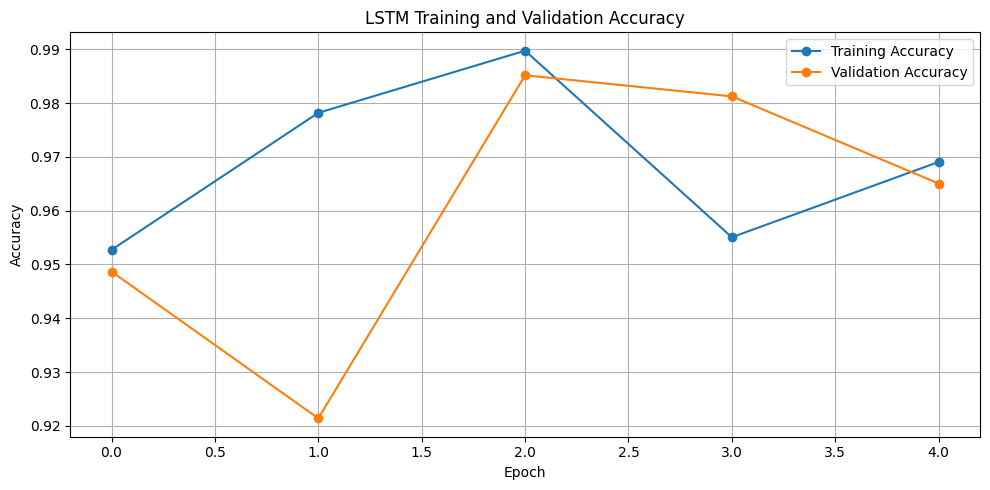

In [8]:
plt.figure(figsize=(10, 5))

plt.plot(history.history["accuracy"], marker="o",
         label="Training Accuracy")
plt.plot(history.history["val_accuracy"], marker="o",
         label="Validation Accuracy")

plt.title("LSTM Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

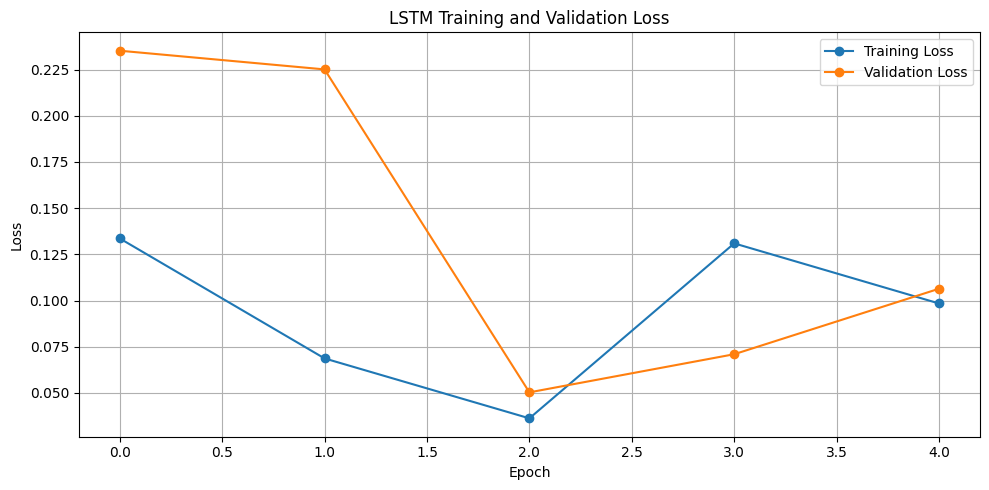

In [9]:
plt.figure(figsize=(10, 5))

plt.plot(history.history["loss"], marker="o",
         label="Training Loss")
plt.plot(history.history["val_loss"], marker="o",
         label="Validation Loss")

plt.title("LSTM Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [10]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Generate prediction probabilities
y_valid_prob = model.predict(X_valid_pad, batch_size=32)

# Convert probabilities into binary labels
y_valid_pred = (y_valid_prob.ravel() >= 0.5).astype(int)

# Calculate evaluation metrics
lstm_accuracy = accuracy_score(y_valid, y_valid_pred)
lstm_macro_f1 = f1_score(y_valid, y_valid_pred, average="macro")
lstm_weighted_f1 = f1_score(y_valid, y_valid_pred, average="weighted")

print(f"LSTM Validation Accuracy: {lstm_accuracy:.4f}")
print(f"LSTM Macro F1: {lstm_macro_f1:.4f}")
print(f"LSTM Weighted F1: {lstm_weighted_f1:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_valid,
    y_valid_pred,
    labels=[0, 1],
    target_names=["Fake News", "Real News"]
))

184/184 ━━━━━━━━━━━━━━━━━━━━ 30s 159ms/step
LSTM Validation Accuracy: 0.9852
LSTM Macro F1: 0.9851
LSTM Weighted F1: 0.9852

Classification Report:
              precision    recall  f1-score   support

   Fake News       0.99      0.98      0.98      2686
   Real News       0.98      0.99      0.99      3179

    accuracy                           0.99      5865
   macro avg       0.99      0.98      0.99      5865
weighted avg       0.99      0.99      0.99      5865



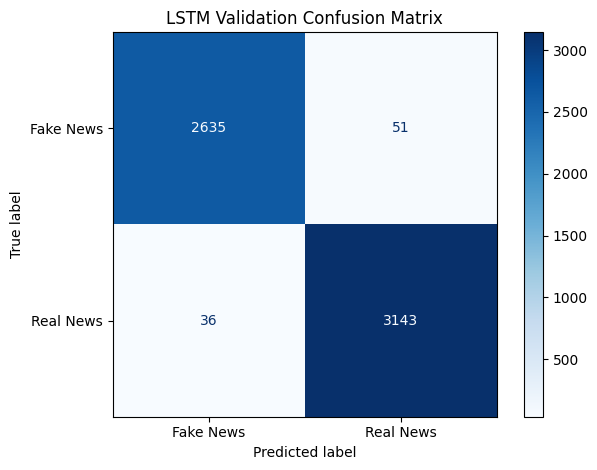

In [11]:
cm = confusion_matrix(y_valid, y_valid_pred, labels=[0, 1])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Fake News", "Real News"]
)

disp.plot(cmap="Blues", values_format="d")

plt.title("LSTM Validation Confusion Matrix")
plt.tight_layout()
plt.show()

In [12]:
import json
from pathlib import Path

Path("models").mkdir(exist_ok=True)

# Save the trained LSTM
model.save("models/lstm_fake_news.keras")

# Save the tokenizer
with open("models/lstm_tokenizer.json", "w", encoding="utf-8") as f:
    f.write(tokenizer.to_json())

# Save validation results
lstm_results = {
    "model": "LSTM",
    "validation_accuracy": float(lstm_accuracy),
    "validation_macro_f1": float(lstm_macro_f1),
    "validation_weighted_f1": float(lstm_weighted_f1),
    "training_time_seconds": float(lstm_training_time),
    "epochs_completed": len(history.history["loss"]),
    "best_epoch": int(np.argmin(history.history["val_loss"]) + 1),
    "vocab_size": VOCAB_SIZE,
    "max_sequence_length": MAX_LENGTH
}

with open("models/lstm_validation_metrics.json", "w") as f:
    json.dump(lstm_results, f, indent=4)

print("LSTM model, tokenizer, and metrics saved!")

LSTM model, tokenizer, and metrics saved!
